# 1. Library Imports and Setup

In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import torchvision
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random
from sklearn.metrics import confusion_matrix, classification_report


In [29]:
def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 2. Data Preprocessing and Augmentation

In [43]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(0),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# 3. Dataset Loading and Preparation

In [105]:
train_dataset = datasets.CIFAR10(root="./", train=True, transform=train_transform, download=True)
test_dataset = datasets.CIFAR10(root="./", train=False, transform=test_transform, download=True)
print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

Training dataset size: 50000
Testing dataset size: 10000


In [59]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# 4. Dataset Visualization and Exploration

In [95]:
classes = train_dataset.classes
print(classes)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [61]:
print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

Training dataset size: 50000
Testing dataset size: 10000


In [107]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([16, 3, 32, 32])
torch.Size([16])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.49473685..1.5229819].


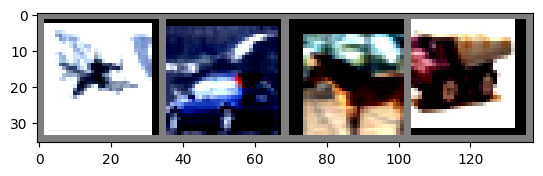

airplane automobile horse truck


In [108]:
def imshow(img):
    img = img / 2 + 0.5 
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images[:4]))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

# 5. CNN Architecture Design

In [66]:
class CNNModel(nn.Module):

    def __init__(self):
        super(CNNModel, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)

        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.pool(torch.relu(self.bn1(self.conv1(x))))

        x = self.pool(torch.relu(self.bn2(self.conv2(x))))

        x = self.pool(torch.relu(self.bn3(self.conv3(x))))

        x = torch.flatten(x, 1)

        x = torch.relu(self.fc1(x))

        x = self.dropout(x)

        x = self.fc2(x)

        return x
    
model = CNNModel()
print(model)

CNNModel(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


# 6. Model Training and Optimization

In [85]:
def train(model, train_loader, epochs=30, learning_rate=0.001):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.0005
    )

    scheduler = optim.lr_scheduler.StepLR(
        optimizer,
        step_size=10,
        gamma=0.5
    )

    loss_history = []
    accuracy_history = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        scheduler.step()

        epoch_loss = total_loss / total
        epoch_accuracy = 100 * correct / total

        loss_history.append(epoch_loss)
        accuracy_history.append(epoch_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    return loss_history, accuracy_history

In [91]:
set_seed(42)

loss_history, accuracy_history = train(
    model,
    train_loader,
    epochs=100,
    learning_rate=0.001,
)

Epoch [1/100] Loss: 0.4665 Accuracy: 84.19%
Epoch [2/100] Loss: 0.4687 Accuracy: 84.23%
Epoch [3/100] Loss: 0.4603 Accuracy: 84.58%
Epoch [4/100] Loss: 0.4548 Accuracy: 84.51%
Epoch [5/100] Loss: 0.4465 Accuracy: 84.98%
Epoch [6/100] Loss: 0.4470 Accuracy: 84.81%
Epoch [7/100] Loss: 0.4467 Accuracy: 84.84%
Epoch [8/100] Loss: 0.4364 Accuracy: 85.18%
Epoch [9/100] Loss: 0.4340 Accuracy: 85.22%
Epoch [10/100] Loss: 0.4267 Accuracy: 85.54%
Epoch [11/100] Loss: 0.4095 Accuracy: 86.13%
Epoch [12/100] Loss: 0.3853 Accuracy: 86.86%
Epoch [13/100] Loss: 0.3720 Accuracy: 87.25%
Epoch [14/100] Loss: 0.3674 Accuracy: 87.16%
Epoch [15/100] Loss: 0.3623 Accuracy: 87.56%
Epoch [16/100] Loss: 0.3617 Accuracy: 87.72%
Epoch [17/100] Loss: 0.3529 Accuracy: 87.91%
Epoch [18/100] Loss: 0.3477 Accuracy: 88.06%
Epoch [19/100] Loss: 0.3498 Accuracy: 87.91%
Epoch [20/100] Loss: 0.3371 Accuracy: 88.40%
Epoch [21/100] Loss: 0.3691 Accuracy: 87.49%
Epoch [22/100] Loss: 0.3636 Accuracy: 87.65%
Epoch [23/100] Loss

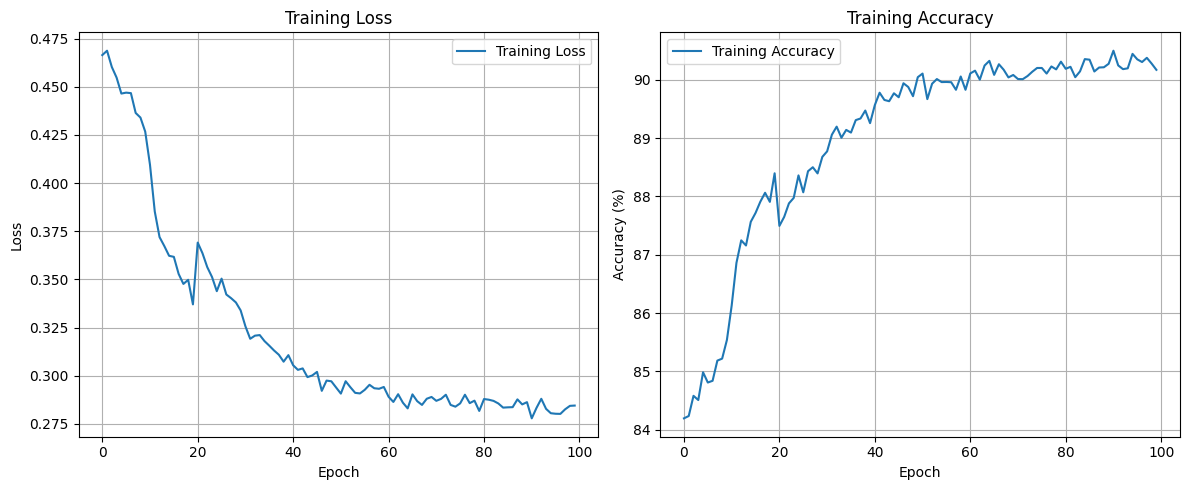

                       0.28454648667141796                                              90.17


In [119]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(loss_history, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(accuracy_history, label="Training Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()
print(F"                       {loss_history[-1]}                                              {accuracy_history[-1]}")

# 	9. Model Evaluation on the Test Set

In [106]:
def test(model, test_loader):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    criterion = torch.nn.CrossEntropyLoss()

    with torch.no_grad():

        for images, labels in test_loader:

            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    average_loss = total_loss / total

    print(f"Test Loss: {average_loss:.4f}")
    print(f"Test Accuracy: {accuracy:.2f}%")

    return average_loss, accuracy


test_loss, test_accuracy = test(model, test_loader)

Test Loss: 0.4171
Test Accuracy: 88.28%


In [94]:
model.eval()
all_preds = []
all_lables = []

with torch.no_grad():
  for images, labels in test_loader:
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)
    all_preds.extend(predicted.numpy())
    all_lables.extend(labels.numpy())

print(classification_report(all_lables, all_preds))

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      1000
           1       0.94      0.94      0.94      1000
           2       0.88      0.82      0.85      1000
           3       0.79      0.76      0.77      1000
           4       0.88      0.88      0.88      1000
           5       0.83      0.83      0.83      1000
           6       0.90      0.92      0.91      1000
           7       0.90      0.92      0.91      1000
           8       0.92      0.93      0.93      1000
           9       0.91      0.93      0.92      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000

